# CS781 Capstone · Phase 5
## Legal Statute Identification

The task is to predict the set of applicable statute IDs for each legal case. I use independent sigmoid outputs with multi-hot targets, since several statutes can apply to the same document.

The experiments start from the four legal language models pretrained in Phase 1. A common hierarchical classification head keeps the document representation comparable across adaptation methods.

| Experiment | Starting model | Adaptation |
|---|---|---|
| Decoder | Decoder-only | Upper two blocks and final layer norm |
| Encoder–decoder | Encoder–decoder | Bottleneck adapters and layer norms |
| Prefix | Bidirectional prefix | LoRMA+ |
| Efficient KD | Efficient-derived compact student | Knowledge distillation from the strongest larger model |

These are the four planned submissions. The default configuration is the prefix experiment. The efficient KD run follows teacher selection from the first three completed models.

### Prepared data and timing evidence

The recorded preparation contains **42,750 training cases, 10,181 development cases, 13,019 test cases and 100 statute IDs**. It uses the original 16,000-token legal BPE tokenizer. The packed cache is reused directly.

Cross-case chunk batching reduced prefix update time from about **26.31 s to 7.65 s**, and encoder–decoder time from **10.49 s to 3.47 s**, at 64 effective cases on T4 ×2. These are short benchmark measurements. A startup check verifies the selected configuration again before fixing its training schedule.


### Kaggle inputs

Attach the bundle from [preparation](phase5_preparation.ipynb) and the matching Phase 1 checkpoint. Set `PREPARED_INPUT` and `CHECKPOINT_INPUT` to their mounted paths if discovery is ambiguous. Set `RESUME_INPUT` when restoring a task checkpoint in a new session. Set `TEACHER_CACHE_INPUT` to the mounted cache ZIP or folder from the [prefix teacher export](phase5_prefix_teacher.ipynb).


## 1. Run configuration

The notebook expects the prepared Phase 5 ZIP or expanded folder and the selected architecture's **original Phase 1 checkpoint**. An existing preparation under `/kaggle/working/cs781_phase5` is reused. The KD student additionally needs the selected teacher-cache ZIP or folder.

`RUN_TAG` identifies a specific experiment. The same tag and configuration resume the local checkpoint. `RESUME_INPUT` restores its task backup in a new session. The original Phase 1 checkpoint and prepared data remain required because task backups store trained tensors rather than another copy of the frozen backbone.

The default five-hour limit covers the training loop, development evaluation and task checkpoint writes. Startup, final test export, backup packaging and teacher-cache export are separate. The update horizon is estimated once and retained on resume.


In [1]:
from pathlib import Path

ARCHITECTURE = "efficient"        # "decoder", "encoder_decoder", "prefix", "efficient"
STUDENT_MODE = "kd"           # Used by efficient only. Optional local control: "gold".
RUN_TAG = "001"
ACTION = "train"              # "train", "export_only", "export_teacher"

PROJECT_ROOT = Path("/kaggle/working/cs781_phase5")
PROJECT_CODE_ROOT = Path("/kaggle/working/cs781_phase5_project")
INPUT_ROOT = Path("/kaggle/input")

PREPARED_INPUT = None
CHECKPOINT_INPUT = None
RESUME_INPUT = None
TEACHER_CACHE_INPUT = '/kaggle/input/datasets/ash9201k/phase5-prefix-teacher-cache'

TARGET_TRAINING_HOURS = 5.0
MAX_RUN_HOURS = 5.0
PLANNED_UPDATES = None         # None estimates a fixed update budget at launch.
EXPORT_TEACHER_CACHE = False

COMPARISON_INPUTS = []         # Optional completed diagnostics ZIPs or expanded folders.
CONFIG_OVERRIDES = {}         # Optional changes for a new experiment, e.g. {"head_lr": 5e-5}.


## 2. Project source

The portable source snapshot expands into readable modules, configuration files and references. The model implementation retains the verified Phase 1 backbones and the measured cross-case batching path. Large training functions are kept outside the notebook.


In [2]:
import base64
import hashlib
import io
import zipfile

SOURCE_ARCHIVE_B64 = "..."
source_bytes = base64.b64decode(SOURCE_ARCHIVE_B64)
assert hashlib.sha256(source_bytes).hexdigest() == "c87cca770e9cfeb6067410eb14c7de661c98204a1551096bbd360a46f4c99b57"
PROJECT_CODE_ROOT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(io.BytesIO(source_bytes)) as archive:
    for member in archive.infolist():
        destination = (PROJECT_CODE_ROOT / member.filename).resolve()
        if not destination.is_relative_to(PROJECT_CODE_ROOT.resolve()):
            raise ValueError("Unexpected project archive path")
        destination.parent.mkdir(parents=True, exist_ok=True)
        destination.write_bytes(archive.read(member))

print("Project source", PROJECT_CODE_ROOT / "src")


Project source /kaggle/working/cs781_phase5_project/src


## 3. Model and optimization settings

Each document supplies up to four 512-position chunks, with overlap 64 and uniform document coverage. Valid chunks from several cases are encoded together, then restored to their original case and chunk order.

For each statute, label-wise attention pools the contextualized chunk representations independently. The output layer therefore produces one logit per statute.

\[
\mathcal L_{\mathrm{gold}} = -\frac{1}{BC}\sum_{i,c}
\left[w_c y_{ic}\log\sigma(z_{ic}) + (1-y_{ic})\log(1-\sigma(z_{ic}))\right].
\]

Positive weights and initial output biases come from the training-label frequencies recorded during preparation. The initial physical batch is 32 cases across both GPUs, with accumulation 2, giving **64 cases per optimizer update**. A smaller physical batch increases accumulation automatically.

AdamW uses head LR `1e-4`, adaptation LR `5e-6` for decoder, `1e-4` for adapters/LoRMA+, and `1e-5` for the compact student. Warmup is 10%, followed by cosine decay to 1% of the peak LR. The remaining shared settings include weight decay 0.01, gradient clipping 1.0, FP16 AMP and EMA decay 0.98.


In [3]:
import copy
import json
import subprocess
import sys
import os
import signal
import pandas as pd
from IPython.display import display, FileLink

all_defaults = json.loads((PROJECT_CODE_ROOT / "configs/experiment_defaults.json").read_text())
if ARCHITECTURE not in all_defaults:
    raise ValueError("Choose one of the four architecture names")
settings = copy.deepcopy(all_defaults[ARCHITECTURE])
settings.update({
    "architecture": ARCHITECTURE, "student_mode": STUDENT_MODE,
    "run_tag": RUN_TAG, "action": ACTION,
    "project_root": str(PROJECT_ROOT), "input_root": str(INPUT_ROOT),
    "prepared_input": PREPARED_INPUT, "checkpoint_input": CHECKPOINT_INPUT,
    "resume_input": RESUME_INPUT, "teacher_cache_input": TEACHER_CACHE_INPUT,
    "target_training_hours": TARGET_TRAINING_HOURS, "max_run_hours": MAX_RUN_HOURS,
    "planned_updates": PLANNED_UPDATES, "export_teacher_cache": EXPORT_TEACHER_CACHE,
})
for name, value in CONFIG_OVERRIDES.items():
    if isinstance(value, dict) and isinstance(settings.get(name), dict):
        settings[name].update(value)
    else:
        settings[name] = value

method = {"decoder": "partial", "encoder_decoder": "adapters", "prefix": "lorma", "efficient": STUDENT_MODE}[ARCHITECTURE]
experiment_id = f"lsi_{ARCHITECTURE}_{method}_{RUN_TAG}"
request_path = PROJECT_CODE_ROOT / "configs" / f"{experiment_id}_request.json"
request_path.write_text(json.dumps(settings, indent=2), encoding="utf-8")
run_dir = PROJECT_ROOT / "runs" / experiment_id

display(pd.DataFrame([{
    "experiment": experiment_id, "action": ACTION,
    "requested_physical_batch": settings["train_batch_cases"],
    "effective_cases": settings["effective_cases"],
    "chunk_microbatch": settings["model_settings"]["chunk_microbatch"],
    "backbone_lr": settings["backbone_lr"], "head_lr": settings["head_lr"],
    "loop_budget_hours": settings["max_run_hours"],
}]))


,experiment,action,requested_physical_batch,effective_cases,chunk_microbatch,backbone_lr,head_lr,loop_budget_hours
0,lsi_efficient_kd_001,train,32,64,64,0.00001,0.0001,5.0


## 4. Prepared-input verification

This stage stages an attached prepared cache when necessary and verifies its packed files, training-row identities, statute columns and tokenizer signature. The selected original Phase 1 checkpoint is checked against its recorded SHA-256 hash before model construction.

The notebook has no raw-data download or tokenization step. All training inputs are taken from the verified preparation.


In [4]:
def run_command(arguments):
    process = subprocess.Popen(
        arguments, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, bufsize=1, start_new_session=True,
    )
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
        returncode = process.wait()
    except KeyboardInterrupt:
        process.send_signal(signal.SIGINT)
        print("Waiting for the worker to finish the current update and save.", flush=True)
        for line in process.stdout:
            print(line, end="", flush=True)
        returncode = process.wait()
    if returncode != 0:
        raise RuntimeError("The worker stopped. The preceding log identifies the failing stage.")

input_report = PROJECT_CODE_ROOT / "current_inputs.json"
run_command([
    sys.executable, "-u", str(PROJECT_CODE_ROOT / "src/lsi_training.py"),
    "--inspect", str(request_path), "--report", str(input_report),
])
inputs_record = json.loads(input_report.read_text())
display(pd.DataFrame([{
    "train_cases": inputs_record["train_cases"], "dev_cases": inputs_record["dev_cases"],
    "test_cases": inputs_record["test_cases"], "statute_labels": len(inputs_record["label_ids"]),
    "tokenizer_vocabulary": inputs_record["tokenizer_signature"]["vocab_size"],
}]))


Verifying original Phase 1 checkpoint efficient
Prepared cases 42750 10181 13019
Statute labels 100


,train_cases,dev_cases,test_cases,statute_labels,tokenizer_vocabulary
0,42750,10181,13019,100,16000


## 5. Training, checkpoint selection and export

The startup probe tests the largest selected chunk geometry, gradient flow and both GPUs. It measures accumulated updates and development inference, then fixes an optimizer-update budget that includes scheduled development passes. Prefix and encoder–decoder begin with the benchmarked 32-case/64-chunk configuration. Decoder and efficient receive their own startup measurement.

Validation uses EMA weights and selects the checkpoint by **development macro-F1 after a global-threshold search**. The run stops at its update budget, wall-time budget or early-stopping condition. Periodic atomic checkpoints preserve raw weights, EMA, AdamW, scaler, data order, RNG states and the original schedule.

Interrupting this cell once requests a clean pause at the next update boundary. A paused run writes its backup and skips final prediction export. Export can then be run using `ACTION = "export_only"`.

The selected checkpoint can precede the final training update. Final predictions always use the selected checkpoint.


In [5]:
run_command([
    sys.executable, "-u", str(PROJECT_CODE_ROOT / "src/lsi_training.py"),
    "--config", str(request_path),
])


Verifying original Phase 1 checkpoint efficient
Run lsi_efficient_kd_001
Physical cases 32 | accumulation 2 | effective cases 64
Fixed update budget 12891
Resuming update 19 of 12891
Update 25/12891 | epoch 0.04 | loss 0.3298 | 1.34s/update | loop 0.7 min
Update 50/12891 | epoch 0.07 | loss 0.3132 | 1.49s/update | loop 1.3 min
Update 75/12891 | epoch 0.11 | loss 0.3283 | 1.53s/update | loop 1.9 min
Update 100/12891 | epoch 0.15 | loss 0.3677 | 1.88s/update | loop 2.6 min
Update 125/12891 | epoch 0.19 | loss 0.3328 | 1.63s/update | loop 3.3 min
Update 150/12891 | epoch 0.22 | loss 0.3466 | 1.56s/update | loop 4.0 min
Update 175/12891 | epoch 0.26 | loss 0.3417 | 1.70s/update | loop 4.6 min
Update 200/12891 | epoch 0.30 | loss 0.3680 | 1.54s/update | loop 5.3 min
Update 225/12891 | epoch 0.34 | loss 0.3499 | 1.63s/update | loop 6.0 min
Update 250/12891 | epoch 0.37 | loss 0.3034 | 1.54s/update | loop 6.7 min
Update 275/12891 | epoch 0.41 | loss 0.3569 | 1.55s/update | loop 7.4 min
Update

## 6. Training record

The plots show the optimization objective, development macro-F1 and the fixed learning-rate trajectory. The global-threshold score is the selection metric. The fixed-0.5 score makes the contribution of threshold selection visible.


,reason,last_update,selected_update,equivalent_epochs,invocation_loop_minutes,cumulative_loop_minutes
0,wall_time_budget,9961,9961,14.912374,299.398439,299.893506


,fixed_schedule_updates,seconds_per_update_at_launch,estimated_dev_minutes,reserved_dev_passes,checkpoint_and_metrics_reserve_minutes
0,12891,1.248185,0.991488,22,10.0


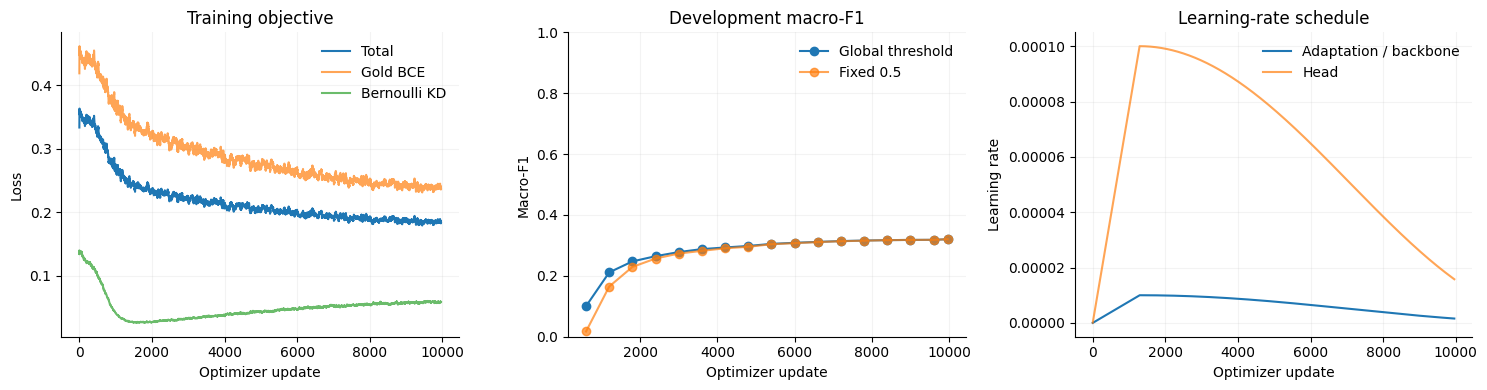

In [6]:
sys.path.insert(0, str(PROJECT_CODE_ROOT / "src"))
from lsi_reporting import plot_history, metric_table, compare_runs

status_path = run_dir / "training_status.json"
if status_path.is_file():
    display(pd.DataFrame([json.loads(status_path.read_text())]))
plan_path = run_dir / "plan.json"
if plan_path.is_file():
    plan = json.loads(plan_path.read_text())
    display(pd.DataFrame([{
        "fixed_schedule_updates": plan["schedule_updates"],
        "seconds_per_update_at_launch": plan["seconds_per_update_at_launch"],
        "estimated_dev_minutes": plan["dev_seconds_at_launch"] / 60,
        "reserved_dev_passes": plan["estimated_validation_passes"],
        "checkpoint_and_metrics_reserve_minutes": plan["save_reserve_minutes"],
    }]))
figure = plot_history(run_dir)
if figure is not None:
    display(figure)
    import matplotlib.pyplot as plt
    plt.close(figure)


## 7. Selected-checkpoint evaluation

After selecting the checkpoint, I fit regularized per-label thresholds on development data. Label thresholds are shrunk toward the selected global threshold and retained when the penalized per-label F1 improves. Labels with insufficient development support retain the global threshold.

The table reports fixed-0.5, global and calibrated results. Calibration gains on development are fitted gains, rather than independent test estimates. The additional clean-development score excludes cases with exact training-text matches while retaining the same fitted thresholds.

The supplied Phase 5 evaluator is run on the final development predictions. Test exports preserve the original IDs and statute IDs, with no duplicate labels. The submission ZIP contains exactly `prediction.json` at its root.


In [7]:
table = metric_table(run_dir)
if not table.empty:
    with pd.option_context("display.float_format", "{:.5f}".format):
        display(table)
    per_label_path = run_dir / "exports/per_label_metrics.csv"
    per_label = pd.read_csv(per_label_path)
    display(per_label.sort_values(["f1", "train_positives"]).head(12))
    export_identity = json.loads((run_dir / "exports/export_identity.json").read_text())
    print("Selected optimizer update", export_identity["selected_update"])
    print("Evaluation weights", export_identity["evaluation_weights"])
    print("Test cases", export_identity["test_cases"])
else:
    print("Selected-checkpoint exports are not available yet. A paused run can be resumed or exported separately.")


,decision_rule,macro_f1,micro_f1,subset_accuracy,mean_predicted_labels
0,Fixed 0.5,0.32035,0.43572,0.02524,5.04184
1,Global threshold,0.32035,0.43572,0.02524,5.04184
2,Regularized label thresholds,0.33147,0.44199,0.02328,5.25911
3,Dev without exact train matches (10063 cases),0.33163,0.44219,0.02335,5.23770


,statute_id,train_positives,dev_positives,predicted_positives,precision,recall,f1
8,8,349,92,0,0.000000,0.000000,0.000000
0,0,343,86,6,0.166667,0.011628,0.021739
65,65,351,105,29,0.103448,0.028571,0.044776
84,84,272,68,21,0.095238,0.029412,0.044944
2,2,367,98,12,0.250000,0.030612,0.054545
99,99,674,176,400,0.060000,0.136364,0.083333
27,27,329,83,66,0.106061,0.084337,0.093960
1,1,1035,258,212,0.122642,0.100775,0.110638
52,52,1084,272,138,0.166667,0.084559,0.112195
41,41,821,205,196,0.117347,0.112195,0.114713


Selected optimizer update 9961
Evaluation weights EMA
Test cases 13019


## 8. Experiment comparison and teacher choice

Completed runs from this project are listed below. Diagnostics from separate Kaggle sessions can be added through `COMPARISON_INPUTS`. Later continuations of the same run ID replace earlier copies in the comparison.

The KD teacher is selected from decoder, encoder–decoder and prefix experiments using the same calibrated development macro-F1. Its exact selected checkpoint is retained in the teacher-cache identity. The efficient-derived student starts afresh from its own Phase 1 initialization.


In [8]:
comparison = compare_runs(PROJECT_ROOT, COMPARISON_INPUTS)
if not comparison.empty:
    display(comparison.drop(columns=["cache_fingerprint", "source"]))
    eligible = comparison[
        comparison["architecture"].isin(["decoder", "encoder_decoder", "prefix"])
        & (comparison["cache_fingerprint"] == inputs_record["cache_fingerprint"])
    ]
    if not eligible.empty:
        choice = eligible.sort_values("dev_macro_f1", ascending=False).iloc[0]
        print("Highest development macro-F1 among available larger models", choice["run_id"])
        print(f"Calibrated development macro-F1 {choice['dev_macro_f1']:.5f}")
else:
    print("No completed exports are available for comparison yet.")


,run_id,architecture,student_mode,last_update,selected_update,dev_macro_f1,dev_micro_f1,dev_subset_accuracy,fixed_05_macro_f1,global_macro_f1,parameters_millions,trainable_millions
0,lsi_efficient_kd_001,efficient,kd,9961,9961,0.331470,0.441992,0.023279,0.320354,0.320354,55.034788,55.034788
1,lsi_efficient_gold_001,efficient,gold,9600,7800,0.320659,0.426961,0.023966,0.310482,0.311575,55.034788,55.034788


## 9. Knowledge-distillation handoff

After completing and comparing the first three experiments, the selected teacher configuration uses:

```python
ACTION = "export_teacher"
```

This loads its selected task checkpoint and exports training logits. It performs no further training and does not repeat test prediction generation. An interrupted cache resumes from its last committed block with the same teacher identity.

The student configuration then uses:

```python
ARCHITECTURE = "efficient"
STUDENT_MODE = "kd"
ACTION = "train"
RESUME_INPUT = None
TEACHER_CACHE_INPUT = "/actual/path/to/lsi_teacher_cache.zip"
```

The teacher ZIP can also be supplied as its automatically expanded Kaggle folder. The student retains original efficient blocks `[0, 7, 15]`. Teacher/student data identities, row order, label order, tokenizer, geometry and checksums are checked before training. The recorded teacher must be larger than the student.

For temperature \(T=2\), each label supplies an independent soft target \(q_c=\sigma(z_{T,c}/T)\). The loss is

\[
\mathcal L = 0.7\mathcal L_{\mathrm{gold}} + 0.3 T^2\,
\frac{1}{BC}\sum_{i,c}\operatorname{KL}
\left[\operatorname{Bern}(q_{ic})\,\Vert\,
\operatorname{Bern}(\sigma(z_{S,ic}/T))\right].
\]

The optional `STUDENT_MODE = "gold"` produces a separate control run. It is not an additional required submission.


## 10. Downloadable run artifacts

The submission is the small prediction-only ZIP. Diagnostics retain source, configuration, histories, probabilities, thresholds and evaluation records. The task backup additionally retains selected and resumable task checkpoints. The original Phase 1 weights and prepared cache remain separate inputs for restoring a backup.

Teacher-cache export produces a separate ZIP containing training logits and the exact teacher identity.


In [9]:
for suffix in ("submission", "diagnostics", "backup", "teacher_cache"):
    artifact = PROJECT_ROOT.parent / f"{experiment_id}_{suffix}.zip"
    if artifact.is_file():
        print(f"{suffix}: {artifact.stat().st_size / 1024**2:.2f} MB")
        print(artifact)
        display(FileLink(str(artifact)))


submission: 0.12 MB
/kaggle/working/lsi_efficient_kd_001_submission.zip


/kaggle/working/lsi_efficient_kd_001_submission.zip

diagnostics: 17.77 MB
/kaggle/working/lsi_efficient_kd_001_diagnostics.zip


/kaggle/working/lsi_efficient_kd_001_diagnostics.zip

backup: 1035.72 MB
/kaggle/working/lsi_efficient_kd_001_backup.zip


/kaggle/working/lsi_efficient_kd_001_backup.zip

## 11. Project code and references

The source package below contains the reusable implementation, experiment configurations, benchmark evidence and reference record for later repository organization. Model weights and prepared task data are exported separately.

The main method references are Chalkidis et al. (2019) for label-wise attention, Houlsby et al. (2019) for bottleneck adapters, Bihany et al. (2025) for LoRMA, and Hinton et al. (2015) for distillation. The exact chunk head, budget, learning rates, EMA settings and threshold shrinkage are project choices. Detailed sources and provenance are recorded in `SOURCES.md`.

- [Legal multi-label classification and label-wise attention](https://aclanthology.org/P19-1636/)
- [Bottleneck adapters](https://proceedings.mlr.press/v97/houlsby19a.html)
- [LoRMA](https://aclanthology.org/2025.findings-acl.527/)
- [Knowledge distillation](https://arxiv.org/abs/1503.02531)
- [Official competition data](https://huggingface.co/datasets/Exploration-Lab/CS-781-Capstone)


In [10]:
code_archive = PROJECT_ROOT.parent / "CS781_Phase5_Project_Code.zip"
with zipfile.ZipFile(code_archive, "w", zipfile.ZIP_DEFLATED) as archive:
    for directory in ("src", "configs", "references", "tests"):
        for path in sorted((PROJECT_CODE_ROOT / directory).glob("*")):
            if path.is_file() and path.suffix in (".py", ".json", ".csv"):
                archive.write(path, "CS781_Phase5/" + path.relative_to(PROJECT_CODE_ROOT).as_posix())
    for filename in ("README.md", "SOURCES.md", "local_validation.json"):
        path = PROJECT_CODE_ROOT / filename
        if path.is_file():
            archive.write(path, "CS781_Phase5/" + filename)
display(FileLink(str(code_archive)))


/kaggle/working/CS781_Phase5_Project_Code.zip